# SP Digital Marketing Engagement Analytics

This cleaned analysis loads and validates the raw data, prepares the selected
group-post subset, creates polished charts, and saves report-ready figures to
`reports/figures/`.

In [1]:
# ruff: noqa: E402, I001
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

try:
    PROJECT_ROOT = Path(__file__).resolve().parents[1]
    RUNNING_AS_SCRIPT = True
except NameError:
    RUNNING_AS_SCRIPT = False
    PROJECT_ROOT = Path.cwd()
    if not (PROJECT_ROOT / "src").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from sp_digital_marketing.config import FIGURES_DIR  # noqa: E402
from sp_digital_marketing.data import (  # noqa: E402
    HOUR_COLUMNS,
    build_population_comparison,
    load_all_data,
    prepare_group_posts,
    validate_dataframes,
)
from sp_digital_marketing.plots import save_comparison_figures  # noqa: E402

## Styling and Helpers

In [2]:
sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "axes.titleweight": "bold",
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "figure.dpi": 120,
    },
)

BLUE = "#2B6CB0"
ORANGE = "#DD6B20"
GREEN = "#2F855A"
RED = "#C53030"
PURPLE = "#6B46C1"
PALETTE = [BLUE, ORANGE, GREEN, RED, PURPLE]


def save_figure(figure: plt.Figure, filename: str) -> Path:
    """Save a chart to the report figures folder."""

    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    output_path = FIGURES_DIR / filename
    figure.savefig(output_path, dpi=160, bbox_inches="tight")
    print(f"Saved {output_path.relative_to(PROJECT_ROOT)}")
    return output_path


def finish_figure(figure: plt.Figure, filename: str) -> Path:
    """Save a figure, display it in notebooks, and close it in script runs."""

    output_path = save_figure(figure, filename)
    if not RUNNING_AS_SCRIPT:
        plt.show()
    plt.close(figure)
    return output_path


def label_bars(axis: plt.Axes) -> None:
    """Add compact value labels to bar charts."""

    for container in axis.containers:
        axis.bar_label(container, fmt="%.0f", padding=3, fontsize=9)

## Load and Validate Data

In [3]:
data = load_all_data()
validate_dataframes(data)

posts = data.posts.copy()
days_summary = data.days_summary.copy()
daily_engagement = data.daily_engagement.copy()
time_of_day = data.time_of_day.copy()

print("Data loaded and validated.")
print(f"Posts: {len(posts):,}")
print(f"Daily engagement rows: {len(daily_engagement):,}")

Data loaded and validated.
Posts: 100
Daily engagement rows: 28


## Dataset Overview

In [4]:
metric_summary = posts[["Comments", "Reactions", "Views"]].agg(
    ["count", "mean", "median", "max", "sum"]
)
print(metric_summary.round(2))

        Comments  Reactions    Views
count     100.00     100.00   100.00
mean        1.92       6.89    82.08
median      1.00       6.00    85.00
max         7.00      15.00   122.00
sum       192.00     689.00  8208.00


## Selected Group Posts

The selected group-post subset is identified by `Member == "Phyo Yadana Khaing"`.
Dates and post types are curated in the reusable project helper because those
fields were not present as clean columns in the raw post export.

In [5]:
group_posts = prepare_group_posts(posts)
group_posts_table = group_posts[
    [
        "Date",
        "Type",
        "Comments",
        "Reactions",
        "Views",
        "Engagement",
        "EngagementRate",
        "Duration of Post",
    ]
].sort_values("Date")

print(group_posts_table.to_string(index=False))

      Date   Type  Comments  Reactions  Views  Engagement  EngagementRate  Duration of Post
2025-01-08 Images         1          8     93           9            9.68                16
2025-01-11 Images         1          7     88           8            9.09                13
2025-01-12  Video         1          5     90           6            6.67                12
2025-01-14  Video         1          6     81           7            8.64                10
2025-01-16  Video         2          6    100           8            8.00                 8
2025-01-18  Video         1          5     83           6            7.23                 6
2025-01-19  Video         2          6     79           8           10.13                 5


## Chart 1: Average Performance by Post Type

Saved reports\figures\post_type_performance.png


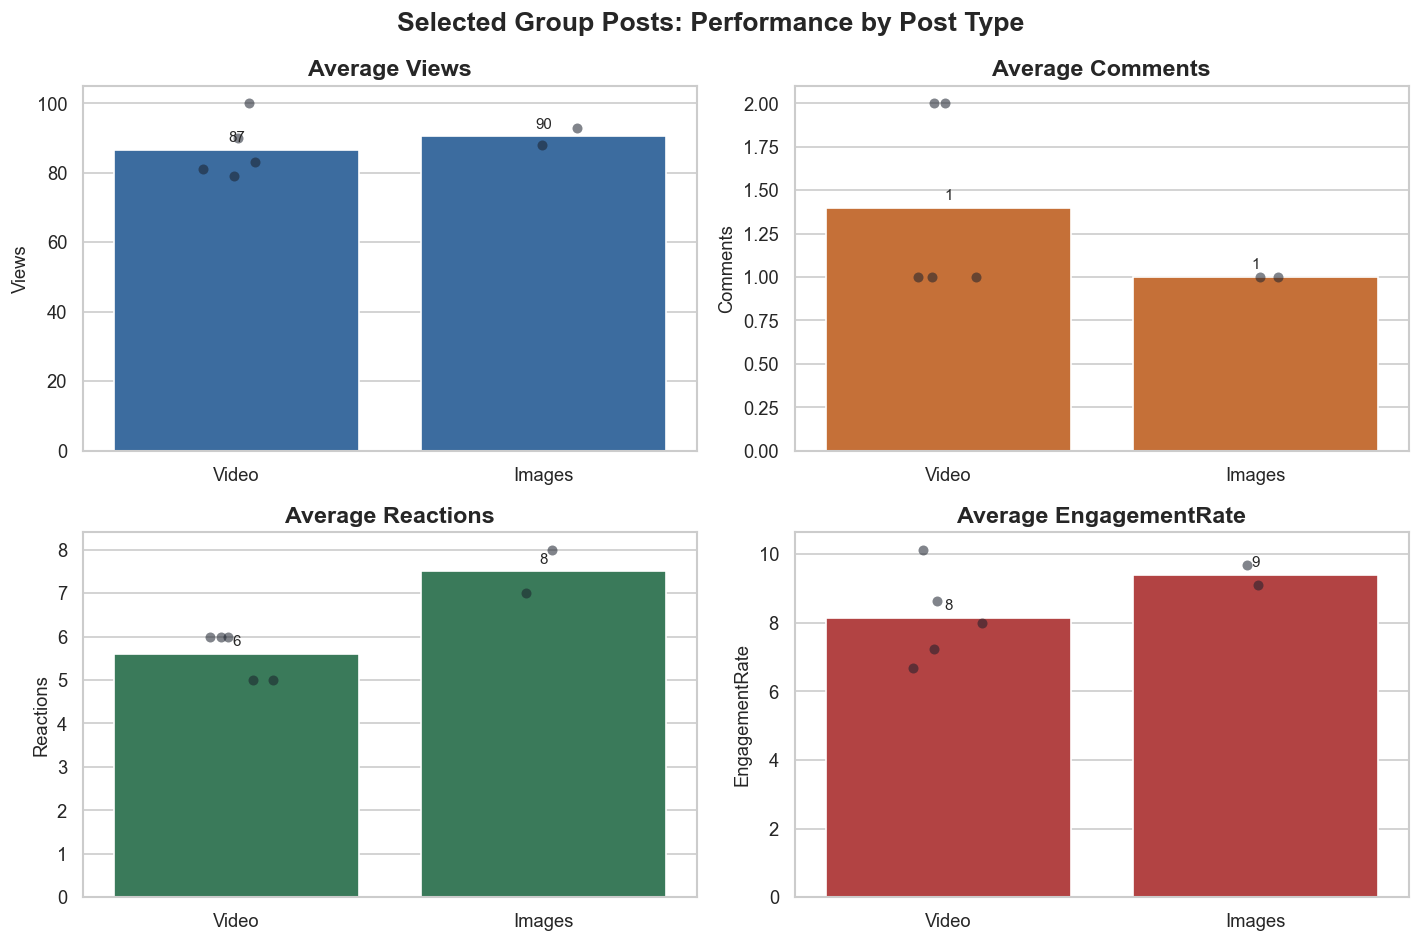

WindowsPath('C:/Users/kunmi/IDM/reports/figures/post_type_performance.png')

In [6]:
performance_metrics = ["Views", "Comments", "Reactions", "EngagementRate"]
figure, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for axis, metric, color in zip(axes, performance_metrics, PALETTE[:4], strict=True):
    sns.barplot(
        data=group_posts,
        x="Type",
        y=metric,
        estimator="mean",
        errorbar=None,
        color=color,
        ax=axis,
    )
    sns.stripplot(
        data=group_posts,
        x="Type",
        y=metric,
        color="#1A202C",
        alpha=0.55,
        jitter=0.12,
        size=6,
        ax=axis,
    )
    label_bars(axis)
    axis.set_title(f"Average {metric}")
    axis.set_xlabel("")
    axis.grid(axis="x", visible=False)

figure.suptitle("Selected Group Posts: Performance by Post Type", fontsize=16, weight="bold")
figure.tight_layout()
finish_figure(figure, "post_type_performance.png")

## Chart 2: Views, Reactions, and Comments Relationship

Saved reports\figures\views_reactions_scatter.png


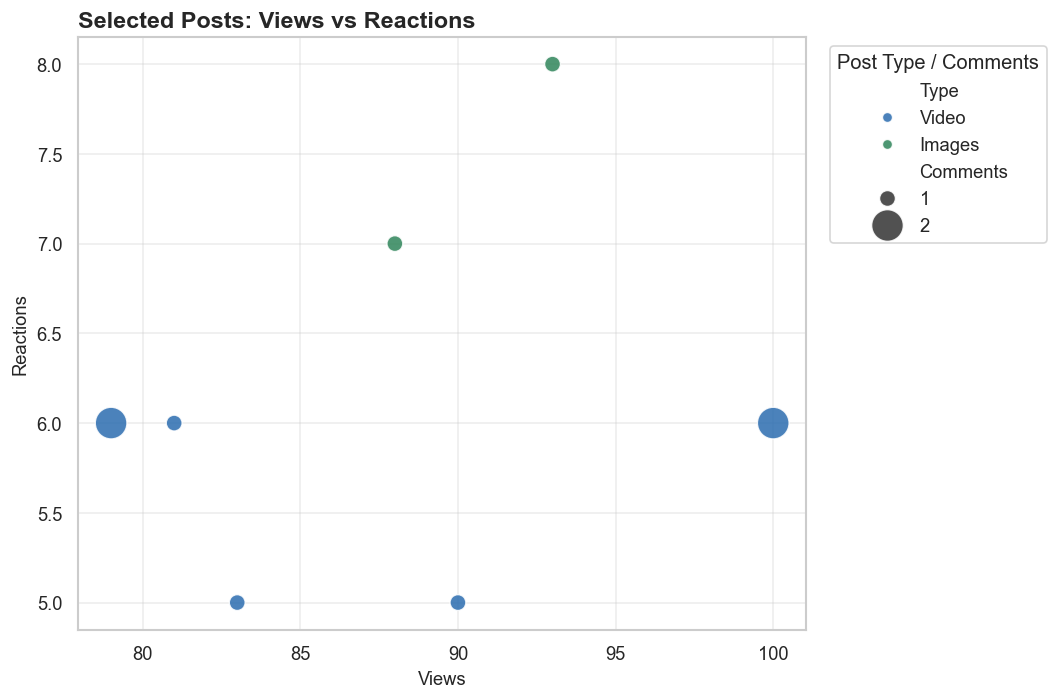

WindowsPath('C:/Users/kunmi/IDM/reports/figures/views_reactions_scatter.png')

In [7]:
figure, axis = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=group_posts,
    x="Views",
    y="Reactions",
    hue="Type",
    size="Comments",
    sizes=(90, 360),
    palette={"Video": BLUE, "Images": GREEN},
    alpha=0.85,
    edgecolor="white",
    linewidth=0.8,
    ax=axis,
)

axis.set_title("Selected Posts: Views vs Reactions", loc="left")
axis.set_xlabel("Views")
axis.set_ylabel("Reactions")
axis.grid(alpha=0.35)
axis.legend(title="Post Type / Comments", bbox_to_anchor=(1.02, 1), loc="upper left")
figure.tight_layout()
finish_figure(figure, "views_reactions_scatter.png")

## Chart 3: Engagement by Day of Week

Saved reports\figures\day_of_week_engagement.png


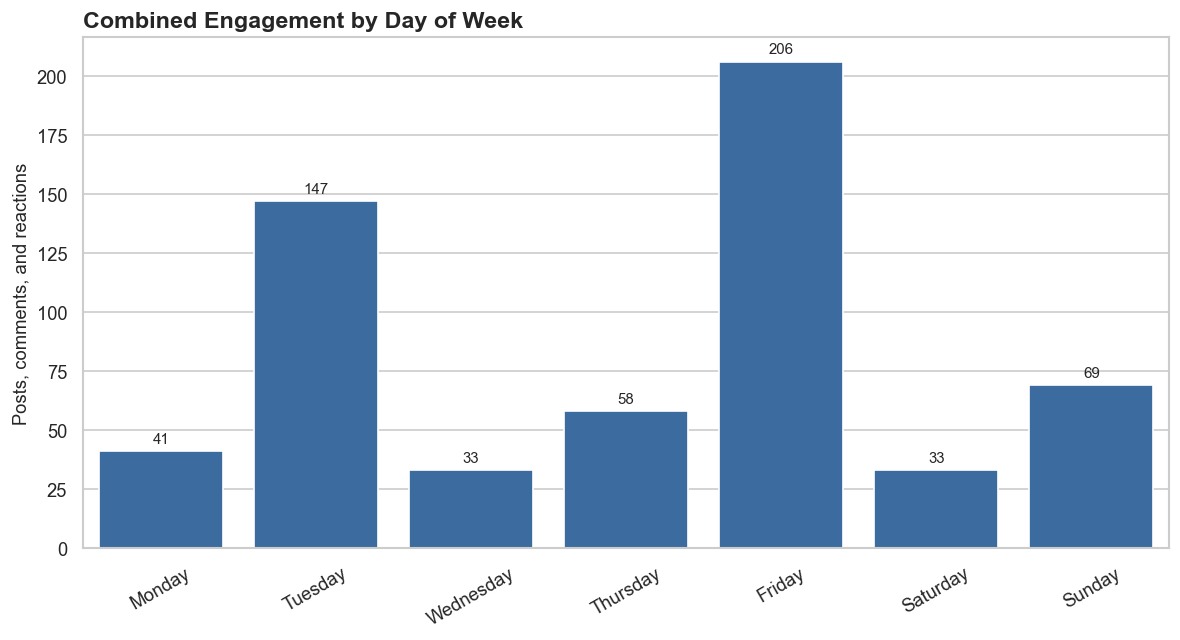

WindowsPath('C:/Users/kunmi/IDM/reports/figures/day_of_week_engagement.png')

In [8]:
figure, axis = plt.subplots(figsize=(10, 5.5))
sns.barplot(
    data=days_summary,
    x="Popular Days",
    y="Posts, Comments and Reactions",
    color=BLUE,
    ax=axis,
)

label_bars(axis)
axis.set_title("Combined Engagement by Day of Week", loc="left")
axis.set_xlabel("")
axis.set_ylabel("Posts, comments, and reactions")
axis.tick_params(axis="x", rotation=30)
axis.grid(axis="x", visible=False)
figure.tight_layout()
finish_figure(figure, "day_of_week_engagement.png")

## Chart 4: Daily Engagement Trend

Saved reports\figures\daily_engagement_trend.png


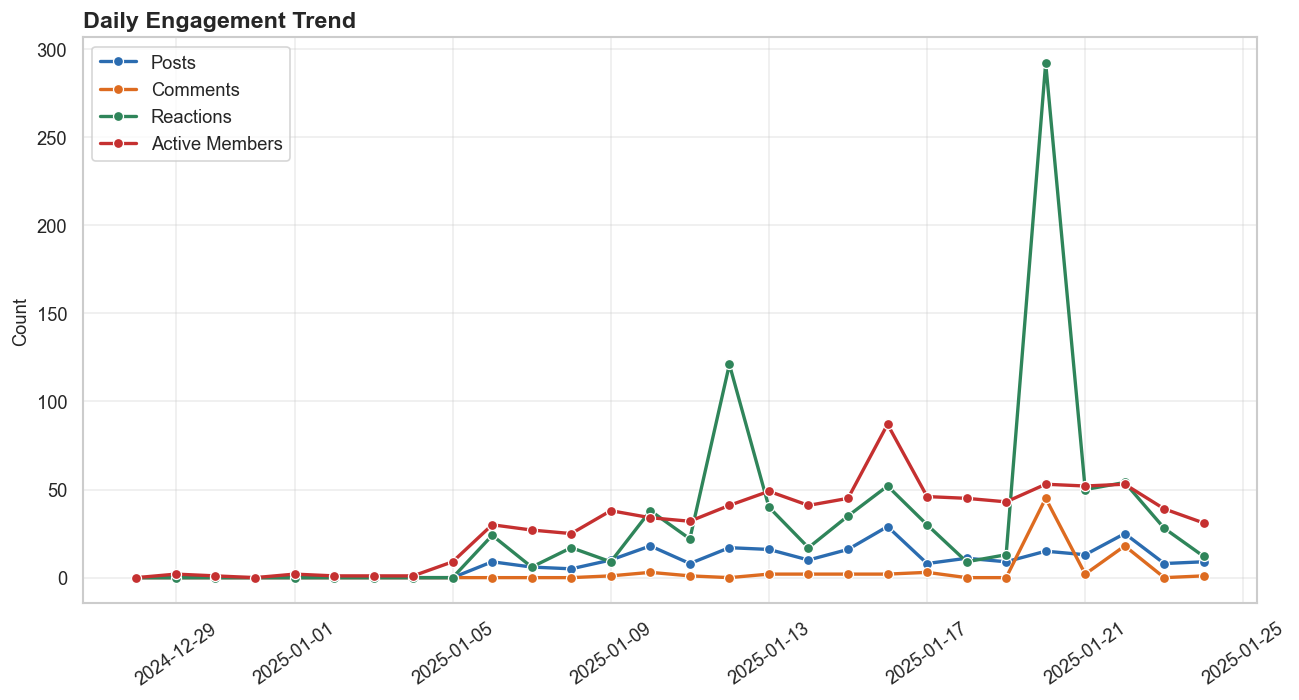

WindowsPath('C:/Users/kunmi/IDM/reports/figures/daily_engagement_trend.png')

In [9]:
daily_engagement["Date"] = pd.to_datetime(daily_engagement["Date"], dayfirst=True)
daily_long = daily_engagement.melt(
    id_vars="Date",
    value_vars=["Posts", "Comments", "Reactions", "Active Members"],
    var_name="Metric",
    value_name="Count",
)

figure, axis = plt.subplots(figsize=(11, 6))
sns.lineplot(
    data=daily_long,
    x="Date",
    y="Count",
    hue="Metric",
    marker="o",
    linewidth=2,
    palette=PALETTE[:4],
    ax=axis,
)

axis.set_title("Daily Engagement Trend", loc="left")
axis.set_xlabel("")
axis.set_ylabel("Count")
axis.tick_params(axis="x", rotation=35)
axis.legend(title="")
axis.grid(alpha=0.35)
figure.tight_layout()
finish_figure(figure, "daily_engagement_trend.png")

## Chart 5: Time of Day Heatmap

Saved reports\figures\time_of_day_heatmap.png


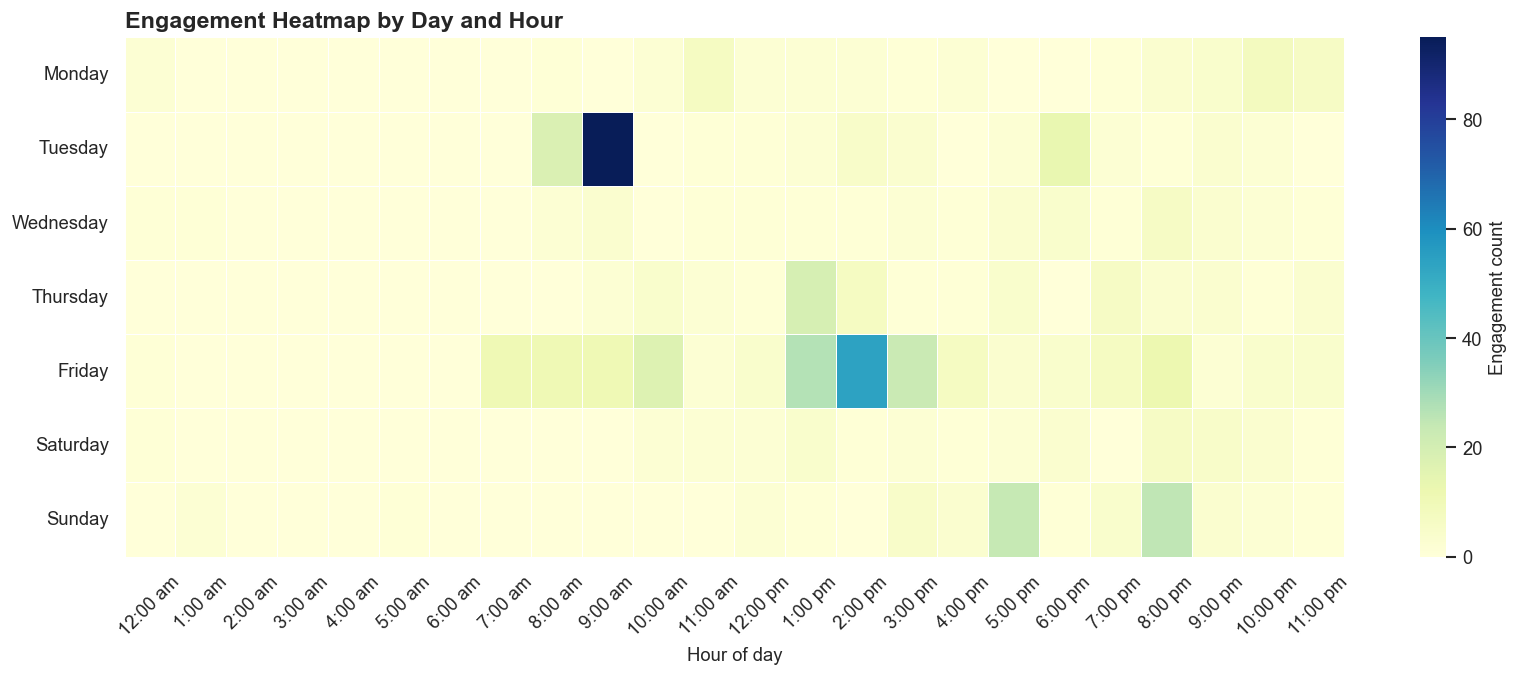

WindowsPath('C:/Users/kunmi/IDM/reports/figures/time_of_day_heatmap.png')

In [10]:
time_matrix = time_of_day.set_index("Popular Times")[HOUR_COLUMNS]

figure, axis = plt.subplots(figsize=(14, 5.8))
sns.heatmap(
    time_matrix,
    cmap="YlGnBu",
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "Engagement count"},
    ax=axis,
)

axis.set_title("Engagement Heatmap by Day and Hour", loc="left")
axis.set_xlabel("Hour of day")
axis.set_ylabel("")
axis.tick_params(axis="x", rotation=45)
figure.tight_layout()
finish_figure(figure, "time_of_day_heatmap.png")

## Chart 6: Selected Posts vs Wider Population

           Comments                  Reactions                  Views         \
              count  mean median max     count  mean median max count   mean   
Dataset                                                                        
Our Post          7  1.29    1.0   2         7  6.14    6.0   8     7  87.71   
Population       93  1.97    1.0   7        93  6.95    7.0  15    93  81.66   

                        
           median  max  
Dataset                 
Our Post     88.0  100  
Population   84.0  122  


Saved reports\figures\population_comparison_overview.png


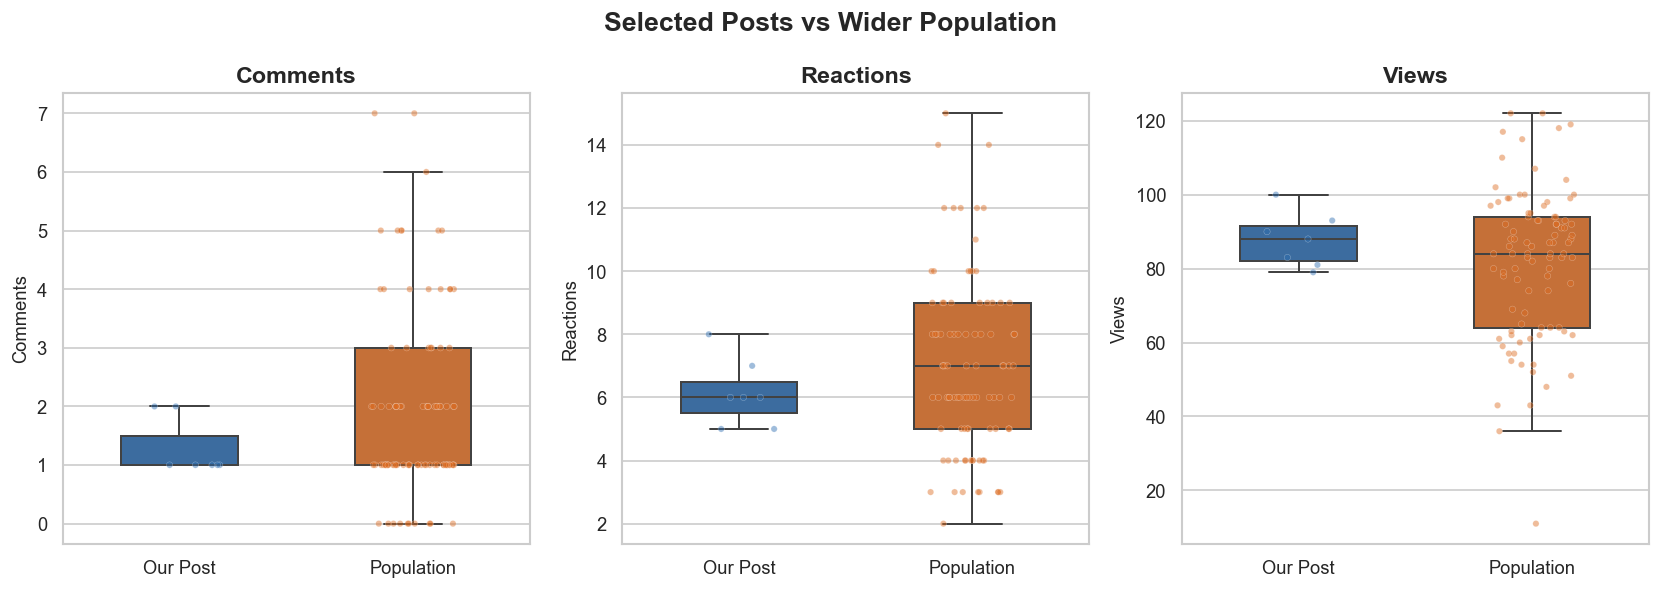

Saved reports\figures\reactions_comparison.png
Saved reports\figures\views_comparison.png
Saved reports\figures\comments_comparison.png


In [11]:
comparison = build_population_comparison(posts)
comparison_summary = comparison.groupby("Dataset")[["Comments", "Reactions", "Views"]].agg(
    ["count", "mean", "median", "max"]
)
print(comparison_summary.round(2))

comparison_palette = {"Our Post": BLUE, "Population": ORANGE}
figure, axes = plt.subplots(1, 3, figsize=(14, 5), sharex=True)

for axis, metric in zip(axes, ["Comments", "Reactions", "Views"], strict=True):
    sns.boxplot(
        data=comparison,
        x="Dataset",
        y=metric,
        hue="Dataset",
        palette=comparison_palette,
        width=0.5,
        fliersize=0,
        linewidth=1.2,
        ax=axis,
    )
    sns.stripplot(
        data=comparison,
        x="Dataset",
        y=metric,
        hue="Dataset",
        palette=comparison_palette,
        jitter=0.18,
        alpha=0.45,
        size=3.8,
        edgecolor="white",
        linewidth=0.25,
        ax=axis,
        legend=False,
    )
    if axis.legend_:
        axis.legend_.remove()
    axis.set_title(metric)
    axis.set_xlabel("")
    axis.grid(axis="x", visible=False)

figure.suptitle("Selected Posts vs Wider Population", fontsize=16, weight="bold")
figure.tight_layout()
finish_figure(figure, "population_comparison_overview.png")

for output_path in save_comparison_figures(data):
    print(f"Saved {output_path.relative_to(PROJECT_ROOT)}")

## Key Takeaways

- Friday has the highest combined day-of-week engagement in the current dataset.
- The time-of-day heatmap shows concentrated engagement windows instead of evenly
  spread activity across all hours.
- Views, comments, and reactions are related but should not be treated as the
  same signal; each metric captures a different level of audience response.
- The selected group-post subset is small, so comparisons should be presented
  as exploratory findings rather than final population-level proof.

In [12]:
top_by_views = posts.sort_values("Views", ascending=False).head(5)
top_by_engagement = posts.assign(Engagement=posts["Comments"] + posts["Reactions"]).sort_values(
    "Engagement", ascending=False
).head(5)

print("Top 5 posts by views")
print(top_by_views[["Member", "Comments", "Reactions", "Views"]].to_string(index=False))
print("\nTop 5 posts by engagement")
print(
    top_by_engagement[["Member", "Comments", "Reactions", "Views", "Engagement"]].to_string(
        index=False
    )
)

Top 5 posts by views
       Member  Comments  Reactions  Views
   Melyrr Ree         7          9    122
   Andrea Gab         3          6    122
Zeenath Begum         5         12    119
   Andrea Gab         1          3    118
   Andrea Gab         2          7    117

Top 5 posts by engagement
           Member  Comments  Reactions  Views  Engagement
       Ilan Faris         5         14     91          19
Nauratul Insyirah         4         15    100          19
         Elsa Foo         6         12    104          18
      Hannah Chua         7         10    115          17
Nauratul Insyirah         3         14     94          17
